<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/1_foundations/dynamics_relativity/make_figures_ch07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Dynamics and Relativity* — `make_figures_ch07.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Dynamics & Relativity — Chapter 7: Special Relativity
## Figure Generator

Generates all 14 figures for Chapter 7 and saves them to `ch07_figures/`.

**How to use:**
1. Run all cells top-to-bottom (`Runtime → Run all` or `Ctrl+F9`).
2. Each figure is displayed inline as it is generated.
3. Run the final cell to package all figures into `ch07_figures.zip` and download.

## 0. Setup

In [1]:
import os
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
from matplotlib.lines import Line2D

FIG_DIR = 'ch07_figures'
os.makedirs(FIG_DIR, exist_ok=True)

# Colour palette (matches dark revealjs theme)
DARK_BG = '#1a1a2e'
BLUE    = '#7ec8e3'
YELLOW  = '#f9c74f'
GREEN   = '#90ee90'
RED     = '#e07070'
DIM     = '#aaaaaa'
WHITE   = '#ffffff'

def base_style():
    plt.rcParams.update({
        'figure.facecolor': DARK_BG,
        'axes.facecolor':   DARK_BG,
        'axes.edgecolor':   DIM,
        'axes.labelcolor':  WHITE,
        'xtick.color':      DIM,
        'ytick.color':      DIM,
        'text.color':       WHITE,
        'grid.color':       '#333355',
        'grid.linestyle':   '--',
        'grid.alpha':       0.5,
        'font.family':      'sans-serif',
        'font.size':        12,
        'mathtext.fontset': 'stix',
    })

def savefig(name):
    """Save current figure to FIG_DIR (keep it open for inline display)."""
    path = os.path.join(FIG_DIR, name)
    plt.savefig(path, dpi=150, bbox_inches='tight')
    print(f'  Saved: {name}')

print('Setup complete. Figures will be saved to:', FIG_DIR)



Setup complete. Figures will be saved to: ch07_figures


---
## Fig 1 — Galilean vs. Lorentz Transformation

  Saved: fig_galilean_vs_lorentz.png


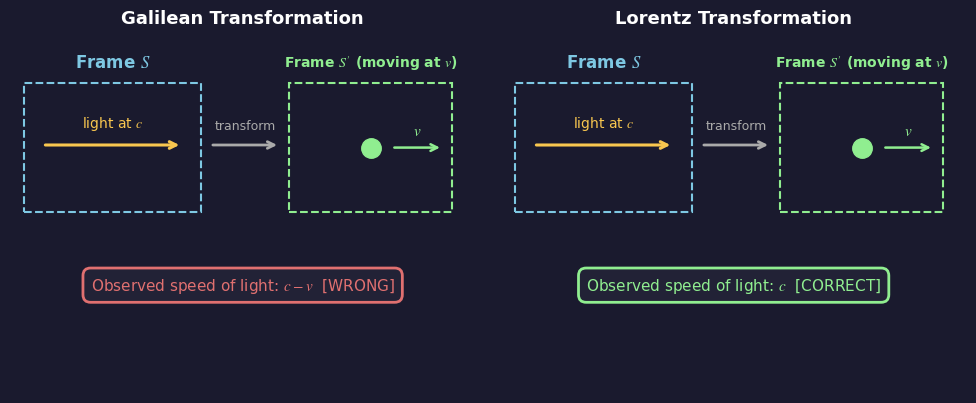

In [2]:
def fig_galilean_vs_lorentz():
    base_style()
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

    titles  = ['Galilean Transformation', 'Lorentz Transformation']
    results = ['Observed speed of light: $c - v$  [WRONG]',
               'Observed speed of light: $c$  [CORRECT]']
    colors  = [RED, GREEN]

    for ax, title, result, col in zip(axes, titles, results, colors):
        ax.set_xlim(0, 10)
        ax.set_ylim(0, 7)
        ax.axis('off')
        ax.set_facecolor(DARK_BG)

        # Frame S box
        ax.add_patch(plt.Rectangle((0.3, 3.5), 3.8, 2.5, fill=False,
                                   edgecolor=BLUE, lw=1.5, linestyle='--'))
        ax.text(2.2, 6.3, r'Frame $S$', color=BLUE,
                fontsize=12, ha='center', fontweight='bold')
        ax.annotate('', xy=(3.7, 4.8), xytext=(0.7, 4.8),
                    arrowprops=dict(arrowstyle='->', color=YELLOW, lw=2.2))
        ax.text(2.2, 5.15, r'light at $c$', color=YELLOW,
                fontsize=10, ha='center')

        # Frame S' box (moving)
        ax.add_patch(plt.Rectangle((6.0, 3.5), 3.5, 2.5, fill=False,
                                   edgecolor=GREEN, lw=1.5, linestyle='--'))
        ax.text(7.75, 6.3, r"Frame $S'$ (moving at $v$)",
                color=GREEN, fontsize=10, ha='center', fontweight='bold')
        ax.plot(7.75, 4.75, 'o', color=GREEN, ms=14, zorder=5)
        ax.annotate('', xy=(9.3, 4.75), xytext=(8.2, 4.75),
                    arrowprops=dict(arrowstyle='->', color=GREEN, lw=1.8))
        ax.text(8.75, 5.0, r'$v$', color=GREEN, fontsize=11, ha='center')

        # Transform arrow
        ax.annotate('', xy=(5.8, 4.8), xytext=(4.3, 4.8),
                    arrowprops=dict(arrowstyle='->', color=DIM, lw=2))
        ax.text(5.05, 5.1, 'transform', color=DIM, fontsize=9, ha='center')

        # Result box
        ax.text(5.0, 2.0, result, color=col, fontsize=11, ha='center',
                bbox=dict(boxstyle='round,pad=0.5', facecolor='#ffffff0a',
                          edgecolor=col, lw=2))
        ax.set_title(title, color=WHITE, fontsize=13, pad=6, fontweight='bold')

    plt.tight_layout()
    savefig('fig_galilean_vs_lorentz.png')
    plt.show()

fig_galilean_vs_lorentz()



---
## Fig 2 — Lorentz Factor $\gamma(\beta)$

  Saved: fig_lorentz_factor.png


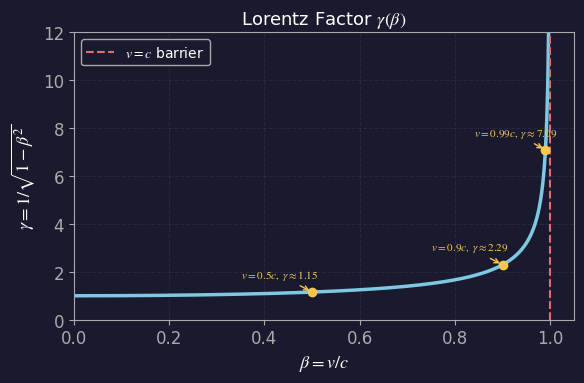

In [3]:
def fig_lorentz_factor():
    base_style()
    fig, ax = plt.subplots(figsize=(6, 4))

    beta  = np.linspace(0, 0.999, 2000)
    gamma = 1.0 / np.sqrt(1 - beta**2)

    ax.plot(beta, gamma, color=BLUE, lw=2.5)
    ax.axvline(1.0, color=RED, lw=1.5, linestyle='--', label=r'$v = c$ barrier')

    for b, label in [(0.5,  r'$v=0.5c,\;\gamma\approx1.15$'),
                     (0.9,  r'$v=0.9c,\;\gamma\approx2.29$'),
                     (0.99, r'$v=0.99c,\;\gamma\approx7.09$')]:
        g = 1 / np.sqrt(1 - b**2)
        ax.plot(b, g, 'o', color=YELLOW, ms=6)
        ax.annotate(label, xy=(b, g), xytext=(b - 0.15, g + 0.6),
                    color=YELLOW, fontsize=8,
                    arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1))

    ax.set_xlabel(r'$\beta = v/c$', fontsize=13)
    ax.set_ylabel(r'$\gamma = 1/\sqrt{1-\beta^2}$', fontsize=13)
    ax.set_title(r'Lorentz Factor $\gamma(\beta)$', color=WHITE, fontsize=13)
    ax.set_xlim(0, 1.05)
    ax.set_ylim(0, 12)
    ax.legend(fontsize=10)
    ax.grid(True)

    plt.tight_layout()
    savefig('fig_lorentz_factor.png')
    plt.show()

fig_lorentz_factor()



---
## Fig 3 — Spacetime Diagram

  Saved: fig_spacetime_diagram.png


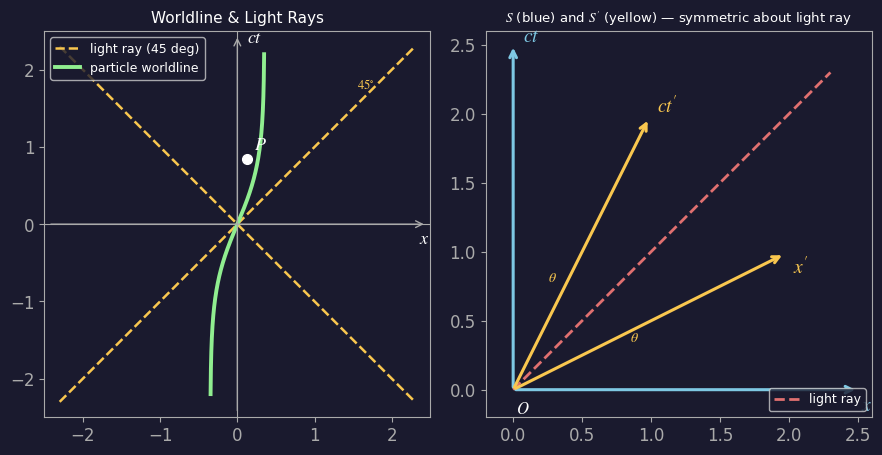

In [4]:
def fig_spacetime_diagram():
    base_style()
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.8))

    # Left: worldline + light rays
    ax = axes[0]
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-2.5, 2.5)
    ax.set_aspect('equal')
    ax.axhline(0, color=DIM, lw=0.8)
    ax.axvline(0, color=DIM, lw=0.8)

    x_lc = np.linspace(-2.3, 2.3, 200)
    ax.plot(x_lc,  x_lc, color=YELLOW, lw=1.8, linestyle='--', label='light ray (45 deg)')
    ax.plot(x_lc, -x_lc, color=YELLOW, lw=1.8, linestyle='--')

    t_wl = np.linspace(-2.2, 2.2, 200)
    x_wl = 0.35 * np.tanh(t_wl * 1.2)
    ax.plot(x_wl, t_wl, color=GREEN, lw=2.8, label='particle worldline')

    ax.plot(0.13, 0.85, 'o', color=WHITE, ms=7, zorder=5)
    ax.text(0.22, 0.97, r'$P$', color=WHITE, fontsize=13, fontweight='bold')

    ax.annotate('', xy=(2.45, 0),  xytext=(-2.45, 0),
                arrowprops=dict(arrowstyle='->', color=DIM, lw=1))
    ax.annotate('', xy=(0, 2.45), xytext=(0, -2.45),
                arrowprops=dict(arrowstyle='->', color=DIM, lw=1))
    ax.text(2.35, -0.25, r'$x$',  color=WHITE, fontsize=13)
    ax.text(0.12,  2.35, r'$ct$', color=WHITE, fontsize=13)
    ax.text(1.55,  1.75, r'$45^{\circ}$', color=YELLOW, fontsize=9)
    ax.set_title('Worldline & Light Rays', color=WHITE, fontsize=11)
    ax.legend(fontsize=9, loc='upper left')

    # Right: S and S' axes
    ax2 = axes[1]
    ax2.set_xlim(-0.2, 2.6)
    ax2.set_ylim(-0.2, 2.6)
    ax2.set_aspect('equal')

    v_over_c = 0.5
    angle = np.arctan(v_over_c)
    L = 2.2

    # S axes (blue)
    ax2.annotate('', xy=(2.5, 0), xytext=(0, 0),
                 arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.2))
    ax2.annotate('', xy=(0, 2.5), xytext=(0, 0),
                 arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.2))
    ax2.text(2.52, -0.15, r'$x$',  color=BLUE, fontsize=14, fontweight='bold')
    ax2.text(0.07,  2.52, r'$ct$', color=BLUE, fontsize=14, fontweight='bold')

    # S' ct' axis: direction (sin theta, cos theta)
    ct_dir = np.array([np.sin(angle), np.cos(angle)])
    ax2.annotate('', xy=L * ct_dir, xytext=(0, 0),
                 arrowprops=dict(arrowstyle='->', color=YELLOW, lw=2.2))
    ax2.text(*(L * ct_dir + [0.06, 0.04]), r"$ct'$",
             color=YELLOW, fontsize=14, fontweight='bold')

    # S' x' axis: direction (cos theta, sin theta)
    xp_dir = np.array([np.cos(angle), np.sin(angle)])
    ax2.annotate('', xy=L * xp_dir, xytext=(0, 0),
                 arrowprops=dict(arrowstyle='->', color=YELLOW, lw=2.2))
    ax2.text(*(L * xp_dir + [0.06, -0.14]), r"$x'$",
             color=YELLOW, fontsize=14, fontweight='bold')

    # Light ray bisector
    x_lr = np.linspace(0, 2.3, 50)
    ax2.plot(x_lr, x_lr, color=RED, lw=2, linestyle='--', label='light ray')

    # Equal angle annotations
    ax2.text(0.85, 0.35, r'$\theta$', color=YELLOW, fontsize=10)
    ax2.text(0.25, 0.78, r'$\theta$', color=YELLOW, fontsize=10)
    ax2.text(0.02, -0.17, r'$O$', color=WHITE, fontsize=12)
    ax2.set_title(r"$S$ (blue) and $S'$ (yellow) — symmetric about light ray",
                  color=WHITE, fontsize=9.5)
    ax2.legend(fontsize=9, loc='lower right')

    plt.tight_layout()
    savefig('fig_spacetime_diagram.png')
    plt.show()

fig_spacetime_diagram()



---
## Fig 4 — Simultaneity

  Saved: fig_simultaneity.png


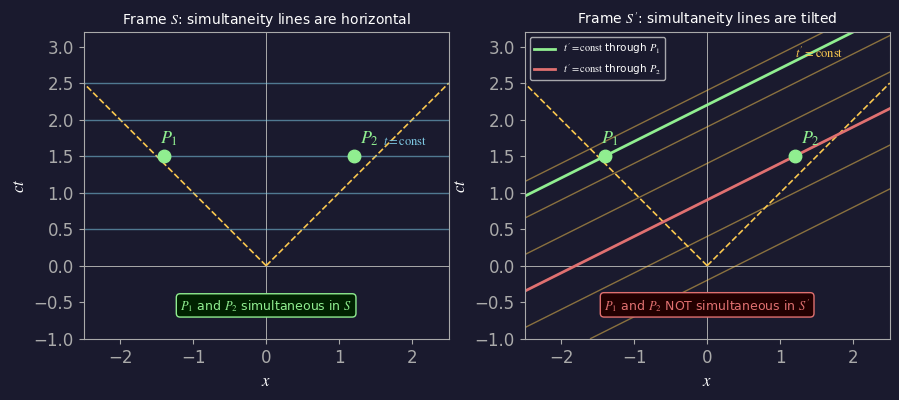

In [5]:
def fig_simultaneity():
    base_style()
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.8))
    v_c = 0.5

    P1 = (-1.4, 1.5)
    P2 = ( 1.2, 1.5)

    for ax, show_primed in zip(axes, [False, True]):
        ax.set_xlim(-2.5, 2.5)
        ax.set_ylim(-1.0, 3.2)
        ax.set_aspect('equal')
        ax.axhline(0, color=DIM, lw=0.7)
        ax.axvline(0, color=DIM, lw=0.7)

        # Light cone
        for sgn in [1, -1]:
            ax.plot([0, sgn * 2.5], [0, 2.5], color=YELLOW, lw=1.2, linestyle='--')

        # Events (simultaneous in S)
        ax.plot(*P1, 'o', color=GREEN, ms=9, zorder=5)
        ax.plot(*P2, 'o', color=GREEN, ms=9, zorder=5)
        ax.text(P1[0] - 0.05, P1[1] + 0.18, r'$P_1$',
                color=GREEN, fontsize=13, fontweight='bold')
        ax.text(P2[0] + 0.08, P2[1] + 0.18, r'$P_2$',
                color=GREEN, fontsize=13, fontweight='bold')

        if not show_primed:
            for y_val in [0.5, 1.0, 1.5, 2.0, 2.5]:
                ax.axhline(y_val, color=BLUE, lw=1.0, alpha=0.55)
            ax.text(1.6, 1.65, r'$t = \mathrm{const}$', color=BLUE, fontsize=9)
            ax.text(0, -0.6, r'$P_1$ and $P_2$ simultaneous in $S$',
                    color=GREEN, fontsize=9, ha='center',
                    bbox=dict(boxstyle='round,pad=0.3',
                              facecolor='#002200', edgecolor=GREEN, lw=1))
            ax.set_title(r"Frame $S$: simultaneity lines are horizontal",
                         color=WHITE, fontsize=10)
        else:
            # Background tilted simultaneity grid
            for y0 in [-0.2, 0.4, 0.9, 1.4, 1.9, 2.4]:
                x_l  = np.linspace(-2.5, 2.5, 200)
                ct_l = v_c * x_l + y0
                mask = (ct_l >= -1.0) & (ct_l <= 3.2)
                ax.plot(x_l[mask], ct_l[mask], color=YELLOW, lw=1.0, alpha=0.5)
            ax.text(1.2, 2.85, r"$t' = \mathrm{const}$", color=YELLOW, fontsize=9)

            # Highlighted t'=const lines through P1 and P2 (different intercepts)
            c1 = P1[1] - v_c * P1[0]
            c2 = P2[1] - v_c * P2[0]
            x_h = np.linspace(-2.5, 2.5, 200)
            ax.plot(x_h, v_c * x_h + c1, color=GREEN, lw=2.0,
                    label=r"$t'=\mathrm{const}$ through $P_1$")
            ax.plot(x_h, v_c * x_h + c2, color=RED,   lw=2.0,
                    label=r"$t'=\mathrm{const}$ through $P_2$")
            ax.legend(fontsize=7.5, loc='upper left')

            ax.text(0, -0.6, r"$P_1$ and $P_2$ NOT simultaneous in $S'$",
                    color=RED, fontsize=9, ha='center',
                    bbox=dict(boxstyle='round,pad=0.3',
                              facecolor='#220000', edgecolor=RED, lw=1))
            ax.set_title(r"Frame $S'$: simultaneity lines are tilted",
                         color=WHITE, fontsize=10)

        ax.set_xlabel(r'$x$', fontsize=12)
        ax.set_ylabel(r'$ct$', fontsize=12)

    plt.tight_layout()
    savefig('fig_simultaneity.png')
    plt.show()

fig_simultaneity()



---
## Fig 5 — Light Cone & Causality

  Saved: fig_light_cone.png


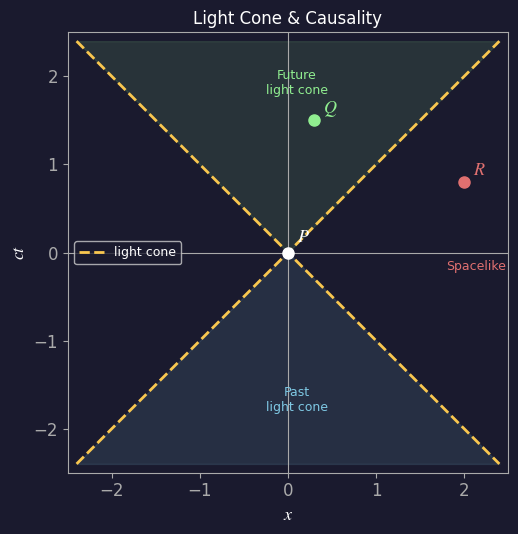

In [6]:
def fig_light_cone():
    base_style()
    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-2.5, 2.5)
    ax.set_aspect('equal')

    t_fill  = np.linspace(0, 2.4, 200)
    ax.fill_betweenx(t_fill, -t_fill, t_fill, color=GREEN, alpha=0.12)
    t_fill2 = np.linspace(-2.4, 0, 200)
    ax.fill_betweenx(t_fill2, t_fill2, -t_fill2, color=BLUE, alpha=0.12)

    x_lc = np.linspace(-2.4, 2.4, 200)
    ax.plot(x_lc,  x_lc, color=YELLOW, lw=2, linestyle='--', label='light cone')
    ax.plot(x_lc, -x_lc, color=YELLOW, lw=2, linestyle='--')

    ax.axhline(0, color=DIM, lw=0.8)
    ax.axvline(0, color=DIM, lw=0.8)

    ax.plot(0, 0, 'o', color=WHITE, ms=8, zorder=5)
    ax.text(0.1, 0.12, r'$P$', color=WHITE, fontsize=13, fontweight='bold')

    ax.plot(0.3, 1.5, 'o', color=GREEN, ms=8, zorder=5)
    ax.text(0.4, 1.58, r'$Q$', color=GREEN, fontsize=13)

    ax.plot(2.0, 0.8, 'o', color=RED, ms=8, zorder=5)
    ax.text(2.1, 0.88, r'$R$', color=RED, fontsize=13)

    ax.text(0.1,  1.8,  'Future\nlight cone', color=GREEN, fontsize=9, ha='center')
    ax.text(0.1, -1.8,  'Past\nlight cone',   color=BLUE,  fontsize=9, ha='center')
    ax.text(1.8, -0.2,  'Spacelike',           color=RED,   fontsize=9)

    ax.set_xlabel(r'$x$', fontsize=13)
    ax.set_ylabel(r'$ct$', fontsize=13)
    ax.set_title('Light Cone & Causality', color=WHITE, fontsize=12)
    ax.legend(fontsize=9)

    plt.tight_layout()
    savefig('fig_light_cone.png')
    plt.show()

fig_light_cone()



---
## Fig 6 — Time Dilation (Light Clock)

  Saved: fig_time_dilation.png


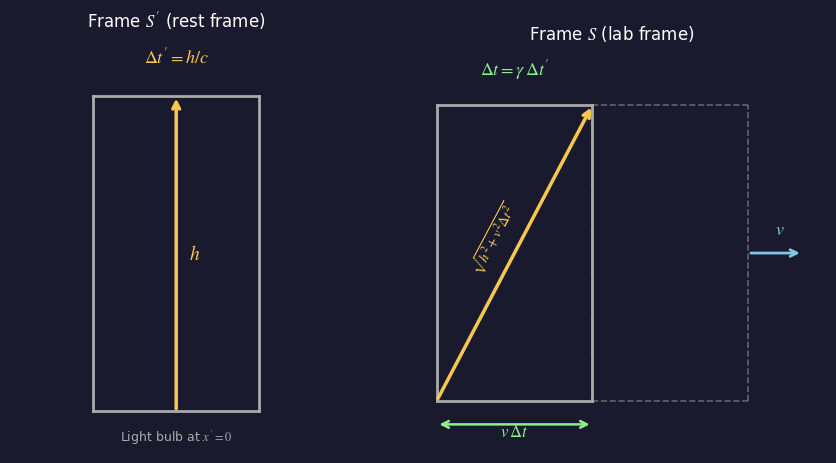

In [7]:
def fig_time_dilation():
    base_style()
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.8))

    # Left: rest frame S'
    ax = axes[0]
    ax.set_xlim(-2, 2)
    ax.set_ylim(-0.5, 4.5)
    ax.set_aspect('equal')
    ax.axis('off')

    for x0, x1, y0, y1 in [(-1, 1, 0, 0), (-1, 1, 3.8, 3.8),
                             (-1, -1, 0, 3.8), (1, 1, 0, 3.8)]:
        ax.plot([x0, x1], [y0, y1], color=DIM, lw=2)

    ax.annotate('', xy=(0, 3.8), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color=YELLOW, lw=2.5))
    ax.text(0.15, 1.9, r'$h$', color=YELLOW, fontsize=14, va='center')
    ax.text(0, 4.2, r"$\Delta t' = h/c$",
            color=YELLOW, fontsize=13, ha='center', fontweight='bold')
    ax.text(0, -0.35, r"Light bulb at $x'=0$",
            color=DIM, fontsize=9, ha='center')
    ax.set_title(r"Frame $S'$ (rest frame)", color=WHITE, fontsize=12, pad=8)

    # Right: lab frame S
    ax2 = axes[1]
    ax2.set_xlim(-0.5, 5)
    ax2.set_ylim(-0.5, 4.5)
    ax2.set_aspect('equal')
    ax2.axis('off')

    dx = 2.0
    for x0, x1, y0, y1 in [(0, 2, 0, 0), (0, 2, 3.8, 3.8),
                             (0, 0, 0, 3.8), (2, 2, 0, 3.8)]:
        ax2.plot([x0, x1], [y0, y1], color=DIM, lw=2)
    for x0, x1, y0, y1 in [(dx, dx+2, 0, 0), (dx, dx+2, 3.8, 3.8),
                             (dx, dx, 0, 3.8), (dx+2, dx+2, 0, 3.8)]:
        ax2.plot([x0, x1], [y0, y1], color=DIM, lw=1.2, linestyle='--', alpha=0.5)

    ax2.annotate('', xy=(dx, 3.8), xytext=(0, 0),
                 arrowprops=dict(arrowstyle='->', color=YELLOW, lw=2.5))
    ax2.text(dx/2 - 0.25, 2.1, r'$\sqrt{h^2 + v^2\Delta t^2}$',
             color=YELLOW, fontsize=10, rotation=62, ha='center', va='center')
    ax2.annotate('', xy=(dx, -0.3), xytext=(0, -0.3),
                 arrowprops=dict(arrowstyle='<->', color=GREEN, lw=1.8))
    ax2.text(dx/2, -0.45, r'$v\,\Delta t$',
             color=GREEN, fontsize=12, ha='center')
    ax2.text(dx/2, 4.2, r'$\Delta t = \gamma\,\Delta t^{\prime}$',
             color=GREEN, fontsize=13, ha='center', fontweight='bold')
    ax2.annotate('', xy=(4.7, 1.9), xytext=(4.0, 1.9),
                 arrowprops=dict(arrowstyle='->', color=BLUE, lw=2))
    ax2.text(4.35, 2.15, r'$v$', color=BLUE, fontsize=13)
    ax2.set_title(r'Frame $S$ (lab frame)', color=WHITE, fontsize=12, pad=8)

    plt.tight_layout()
    savefig('fig_time_dilation.png')
    plt.show()

fig_time_dilation()



---
## Fig 7 — Length Contraction

  Saved: fig_length_contraction.png


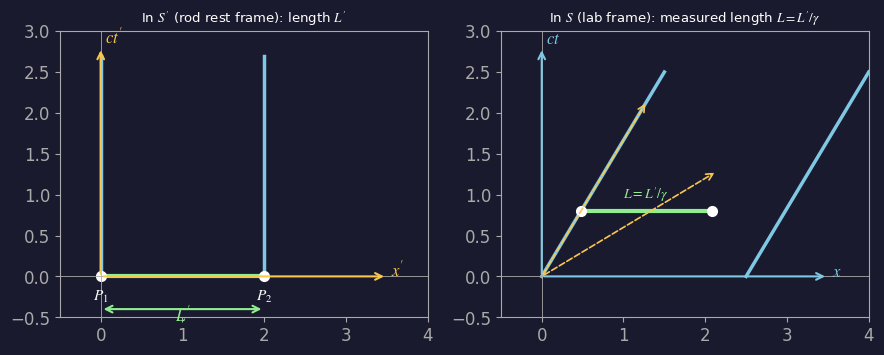

In [8]:
def fig_length_contraction():
    base_style()
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))

    v_c     = 0.6
    gamma   = 1 / np.sqrt(1 - v_c**2)
    L_prime = 2.0
    L       = L_prime / gamma
    angle   = np.arctan(v_c)

    for ax, show_primed in zip(axes, [True, False]):
        ax.set_xlim(-0.5, 4)
        ax.set_ylim(-0.5, 3)
        ax.set_aspect('equal')

        if show_primed:
            ax.annotate('', xy=(3.5, 0), xytext=(0, 0),
                        arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.5))
            ax.annotate('', xy=(0, 2.8), xytext=(0, 0),
                        arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.5))
            ax.text(3.55, 0,    r"$x'$",  color=YELLOW, fontsize=12)
            ax.text(0.05, 2.85, r"$ct'$", color=YELLOW, fontsize=12)

            ax.plot([0, 0],                [0, 2.7], color=BLUE, lw=2.5)
            ax.plot([L_prime, L_prime],    [0, 2.7], color=BLUE, lw=2.5)
            ax.plot([0, L_prime],          [0, 0],   color=GREEN, lw=3)
            ax.plot(0,       0, 'o', color=WHITE, ms=7)
            ax.plot(L_prime, 0, 'o', color=WHITE, ms=7)
            ax.text(-0.1,            -0.3, r'$P_1$', color=WHITE, fontsize=11)
            ax.text(L_prime - 0.1,   -0.3, r'$P_2$', color=WHITE, fontsize=11)
            ax.annotate('', xy=(L_prime, -0.4), xytext=(0, -0.4),
                        arrowprops=dict(arrowstyle='<->', color=GREEN, lw=1.5))
            ax.text(L_prime / 2, -0.55, r"$L'$",
                    color=GREEN, fontsize=12, ha='center')
            ax.set_title(r"In $S'$ (rod rest frame): length $L'$",
                         color=WHITE, fontsize=9.5)
        else:
            ax.annotate('', xy=(3.5, 0), xytext=(0, 0),
                        arrowprops=dict(arrowstyle='->', color=BLUE, lw=1.5))
            ax.annotate('', xy=(0, 2.8), xytext=(0, 0),
                        arrowprops=dict(arrowstyle='->', color=BLUE, lw=1.5))
            ax.text(3.55, 0,    r'$x$',  color=BLUE, fontsize=12)
            ax.text(0.05, 2.85, r'$ct$', color=BLUE, fontsize=12)

            L2 = 2.5
            ax.annotate('', xy=(L2*np.cos(angle), L2*np.sin(angle)), xytext=(0, 0),
                        arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.2,
                                        linestyle='dashed'))
            ax.annotate('', xy=(L2*np.sin(angle), L2*np.cos(angle)), xytext=(0, 0),
                        arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.2,
                                        linestyle='dashed'))

            t_arr = np.linspace(0, 2.5, 50)
            ax.plot(v_c * t_arr,          t_arr, color=BLUE, lw=2.5)
            ax.plot(gamma * L_prime + v_c * t_arr, t_arr, color=BLUE, lw=2.5)

            t_meas  = 0.8
            x1_meas = v_c * t_meas
            ax.plot([x1_meas, x1_meas + L], [t_meas, t_meas], color=GREEN, lw=3)
            ax.plot(x1_meas,     t_meas, 'o', color=WHITE, ms=7)
            ax.plot(x1_meas + L, t_meas, 'o', color=WHITE, ms=7)
            ax.text(x1_meas + L / 2, t_meas + 0.15,
                    r"$L = L'/\gamma$", color=GREEN, fontsize=10, ha='center')
            ax.set_title(r"In $S$ (lab frame): measured length $L = L'/\gamma$",
                         color=WHITE, fontsize=9.5)

        ax.axhline(0, color=DIM, lw=0.6)
        ax.axvline(0, color=DIM, lw=0.6)

    plt.tight_layout()
    savefig('fig_length_contraction.png')
    plt.show()

fig_length_contraction()



---
## Fig 8 — Relativistic Velocity Addition

  Saved: fig_velocity_addition.png


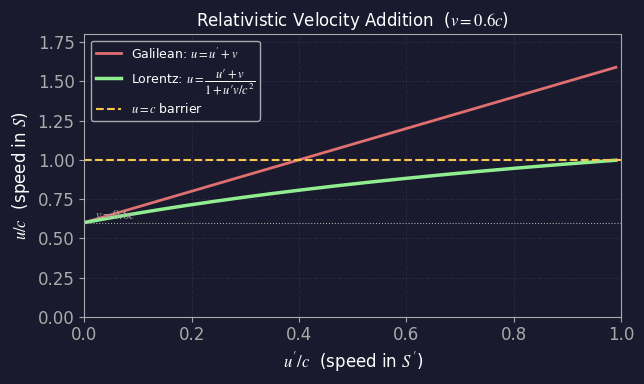

In [9]:
def fig_velocity_addition():
    base_style()
    fig, ax = plt.subplots(figsize=(6.5, 4))

    u_prime    = np.linspace(0, 0.99, 500)
    v          = 0.6
    u_galilean = u_prime + v
    u_lorentz  = (u_prime + v) / (1 + u_prime * v)

    ax.plot(u_prime, u_galilean, color=RED,   lw=2,
            label=r"Galilean: $u = u' + v$")
    ax.plot(u_prime, u_lorentz,  color=GREEN, lw=2.5,
            label=r'Lorentz: $u = \dfrac{u\prime + v}{1 + u\prime v/c^2}$')
    ax.axhline(1.0, color=YELLOW, lw=1.5, linestyle='--', label=r'$u = c$ barrier')
    ax.axhline(v,   color=DIM,    lw=0.8, linestyle=':')
    ax.text(0.02, v + 0.02, r'$v = 0.6c$', color=DIM, fontsize=9)

    ax.set_xlabel(r"$u'/c$  (speed in $S'$)", fontsize=12)
    ax.set_ylabel(r'$u/c$  (speed in $S$)',   fontsize=12)
    ax.set_title(r'Relativistic Velocity Addition  ($v = 0.6c$)',
                 color=WHITE, fontsize=12)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.8)
    ax.legend(fontsize=9, loc='upper left')
    ax.grid(True)

    plt.tight_layout()
    savefig('fig_velocity_addition.png')
    plt.show()

fig_velocity_addition()



---
## Fig 9 — Energy-Momentum Dispersion Relation

  Saved: fig_energy_momentum.png


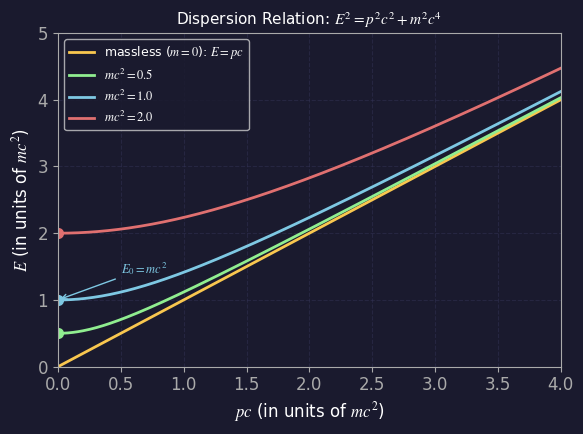

In [10]:
def fig_energy_momentum():
    base_style()
    fig, ax = plt.subplots(figsize=(6, 4.5))

    p = np.linspace(0, 4, 300)

    for m, col, label in [
        (0,   YELLOW, r'massless ($m=0$): $E = pc$'),
        (0.5, GREEN,  r'$mc^2 = 0.5$'),
        (1.0, BLUE,   r'$mc^2 = 1.0$'),
        (2.0, RED,    r'$mc^2 = 2.0$'),
    ]:
        E = np.sqrt(p**2 + m**2)
        ax.plot(p, E, color=col, lw=2, label=label)
        if m > 0:
            ax.plot(0, m, 'o', color=col, ms=7)

    ax.annotate(r'$E_0 = mc^2$', xy=(0, 1.0), xytext=(0.5, 1.4),
                color=BLUE, fontsize=9,
                arrowprops=dict(arrowstyle='->', color=BLUE, lw=1))

    ax.set_xlabel(r'$pc$ (in units of $mc^2$)', fontsize=12)
    ax.set_ylabel(r'$E$ (in units of $mc^2$)',  fontsize=12)
    ax.set_title(r'Dispersion Relation: $E^2 = p^2c^2 + m^2c^4$',
                 color=WHITE, fontsize=11)
    ax.legend(fontsize=9)
    ax.grid(True)
    ax.set_xlim(0, 4)
    ax.set_ylim(0, 5)

    plt.tight_layout()
    savefig('fig_energy_momentum.png')
    plt.show()

fig_energy_momentum()



---
## Fig 10 — Relativistic Momentum & Kinetic Energy

  Saved: fig_relativistic_momentum.png


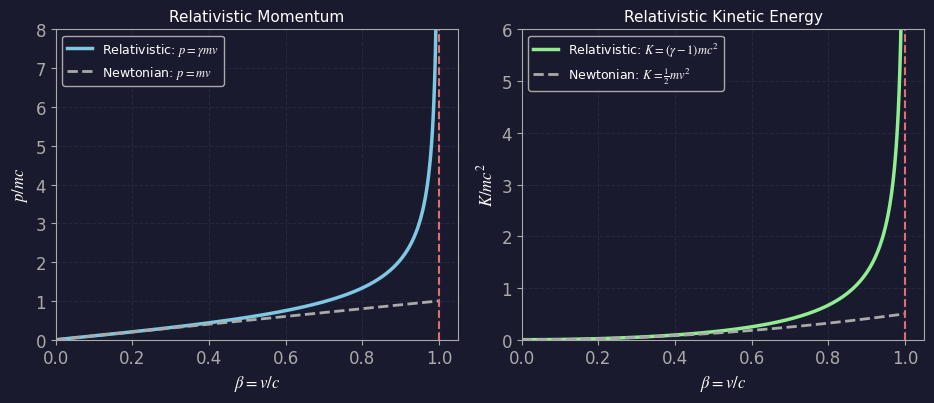

In [11]:
def fig_relativistic_momentum():
    base_style()
    fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2))

    beta  = np.linspace(0, 0.999, 500)
    gamma = 1 / np.sqrt(1 - beta**2)

    ax = axes[0]
    ax.plot(beta, gamma * beta, color=BLUE, lw=2.5,
            label=r'Relativistic: $p = \gamma mv$')
    ax.plot(beta, beta,         color=DIM,  lw=2, linestyle='--',
            label=r'Newtonian: $p = mv$')
    ax.axvline(1, color=RED, lw=1.5, linestyle='--')
    ax.set_xlabel(r'$\beta = v/c$', fontsize=12)
    ax.set_ylabel(r'$p / mc$',      fontsize=12)
    ax.set_title('Relativistic Momentum', color=WHITE, fontsize=11)
    ax.legend(fontsize=9)
    ax.grid(True)
    ax.set_xlim(0, 1.05)
    ax.set_ylim(0, 8)

    ax2 = axes[1]
    ax2.plot(beta, gamma - 1,     color=GREEN, lw=2.5,
             label=r'Relativistic: $K=(\gamma-1)mc^2$')
    ax2.plot(beta, 0.5 * beta**2, color=DIM,   lw=2, linestyle='--',
             label=r'Newtonian: $K=\frac{1}{2}mv^2$')
    ax2.axvline(1, color=RED, lw=1.5, linestyle='--')
    ax2.set_xlabel(r'$\beta = v/c$', fontsize=12)
    ax2.set_ylabel(r'$K / mc^2$',    fontsize=12)
    ax2.set_title('Relativistic Kinetic Energy', color=WHITE, fontsize=11)
    ax2.legend(fontsize=9)
    ax2.grid(True)
    ax2.set_xlim(0, 1.05)
    ax2.set_ylim(0, 6)

    plt.tight_layout()
    savefig('fig_relativistic_momentum.png')
    plt.show()

fig_relativistic_momentum()



---
## Fig 11 — Hyperbolic Motion & Rindler Horizon

  Saved: fig_hyperbolic_motion.png


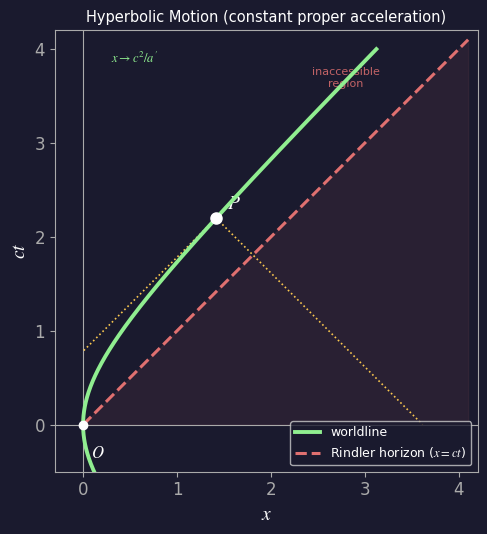

In [12]:
def fig_hyperbolic_motion():
    base_style()
    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.set_xlim(-0.3, 4.2)
    ax.set_ylim(-0.5, 4.2)
    ax.set_aspect('equal')

    # Hyperbolic worldline: x = sqrt(1 + t^2) - 1  (units: c = a' = 1)
    t_arr = np.linspace(-4.0, 4.0, 800)
    x_arr = np.sqrt(1 + t_arr**2) - 1
    ax.plot(x_arr, t_arr, color=GREEN, lw=2.8, label='worldline', zorder=4)

    # Rindler horizon: x = ct
    x_rh = np.linspace(0, 4.1, 100)
    ax.plot(x_rh, x_rh, color=RED, lw=2.2, linestyle='--',
            label=r'Rindler horizon ($x = ct$)', zorder=3)

    # Shade inaccessible region
    t_shade = np.linspace(0, 4.1, 200)
    ax.fill_between(t_shade, 0, t_shade, color=RED, alpha=0.08)

    ax.axhline(0, color=DIM, lw=0.8)
    ax.axvline(0, color=DIM, lw=0.8)

    # Event P and past light cone
    t_P = 2.2
    x_P = np.sqrt(1 + t_P**2) - 1
    ax.plot(x_P, t_P, 'o', color=WHITE, ms=8, zorder=6)
    ax.text(x_P + 0.12, t_P + 0.1, r'$P$', color=WHITE,
            fontsize=14, fontweight='bold')
    for slope in [1, -1]:
        reach = min(t_P, (4.2 - x_P) if slope > 0 else x_P)
        ax.plot([x_P, x_P + slope * reach], [t_P, t_P - reach],
                color=YELLOW, lw=1.2, linestyle=':', zorder=3)

    ax.text(2.8, 3.6, 'inaccessible\nregion', color=RED,
            fontsize=8, ha='center', alpha=0.85)
    ax.text(0.3, 3.85, r'$x \to c^2/a^{\prime}$', color=GREEN, fontsize=9)
    ax.plot(0, 0, 'o', color=WHITE, ms=6, zorder=5)
    ax.text(0.08, -0.35, r'$O$', color=WHITE, fontsize=12)

    ax.set_xlabel(r'$x$', fontsize=14)
    ax.set_ylabel(r'$ct$', fontsize=14)
    ax.set_title(r'Hyperbolic Motion (constant proper acceleration)',
                 color=WHITE, fontsize=10.5)
    ax.legend(fontsize=9, loc='lower right')

    plt.tight_layout()
    savefig('fig_hyperbolic_motion.png')
    plt.show()

fig_hyperbolic_motion()



---
## Fig 12 — Twin Paradox

  Saved: fig_twin_paradox.png


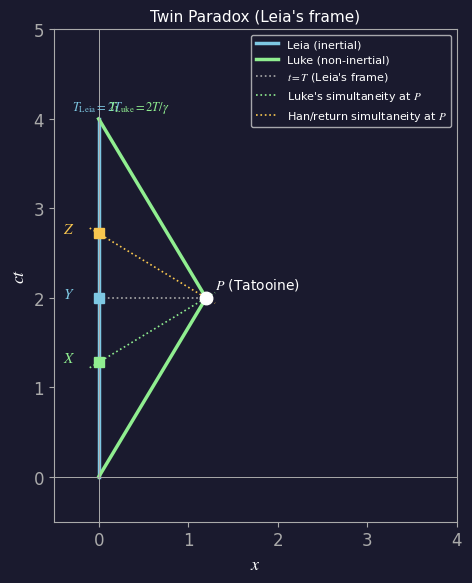

In [13]:
def fig_twin_paradox():
    base_style()
    fig, ax = plt.subplots(figsize=(5, 6))
    ax.set_xlim(-0.5, 4)
    ax.set_ylim(-0.5, 5)
    ax.set_aspect('equal')

    v_c    = 0.6
    T      = 2.0
    x_turn = v_c * T

    ax.plot([0, 0],             [0, 4],        color=BLUE,  lw=2.5,
            label='Leia (inertial)')
    ax.plot([0, x_turn, 0],     [0, T, 2 * T], color=GREEN, lw=2.5,
            label='Luke (non-inertial)')

    ax.plot(x_turn, T, 'o', color=WHITE, ms=9, zorder=5)
    ax.text(x_turn + 0.1, T + 0.1, r'$P$ (Tatooine)', color=WHITE, fontsize=10)

    # Y: Leia's simultaneity at P
    ax.plot([0, x_turn], [T, T], color=DIM, lw=1.2, linestyle=':',
            label=r"$t=T$ (Leia's frame)")
    ax.plot(0, T, 's', color=BLUE, ms=7, zorder=4)
    ax.text(-0.4, T, r'$Y$', color=BLUE, fontsize=11)

    # X: Luke's outbound simultaneity at P
    t_X = T * (1 - v_c**2)
    x_h = np.linspace(-0.1, x_turn + 0.1, 50)
    ax.plot(x_h, v_c * x_h + (T - v_c * x_turn),
            color=GREEN, lw=1.2, linestyle=':',
            label=r"Luke's simultaneity at $P$")
    ax.plot(0, t_X, 's', color=GREEN, ms=7, zorder=4)
    ax.text(-0.4, t_X, r'$X$', color=GREEN, fontsize=11)

    # Z: Return journey simultaneity
    t_Z = T + v_c * x_turn
    ax.plot(x_h, -v_c * x_h + (T + v_c * x_turn),
            color=YELLOW, lw=1.2, linestyle=':',
            label=r"Han/return simultaneity at $P$")
    ax.plot(0, t_Z, 's', color=YELLOW, ms=7, zorder=4)
    ax.text(-0.4, t_Z, r'$Z$', color=YELLOW, fontsize=11)

    ax.text(-0.3, 2 * T + 0.1, r'$T_{\rm Leia} = 2T$',         color=BLUE,  fontsize=9)
    ax.text( 0.1, 2 * T + 0.1, r'$T_{\rm Luke} = 2T/\gamma$',  color=GREEN, fontsize=9)

    ax.axhline(0, color=DIM, lw=0.7)
    ax.axvline(0, color=DIM, lw=0.7)
    ax.set_xlabel(r'$x$', fontsize=13)
    ax.set_ylabel(r'$ct$', fontsize=13)
    ax.set_title("Twin Paradox (Leia's frame)", color=WHITE, fontsize=11)
    ax.legend(fontsize=8, loc='upper right')

    plt.tight_layout()
    savefig('fig_twin_paradox.png')
    plt.show()

fig_twin_paradox()



---
## Fig 13 — Rapidity

  Saved: fig_rapidity.png


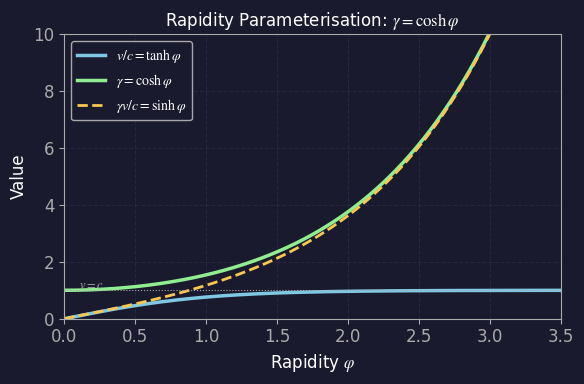

In [14]:
def fig_rapidity():
    base_style()
    fig, ax = plt.subplots(figsize=(6, 4))

    phi = np.linspace(0, 3.5, 300)

    ax.plot(phi, np.tanh(phi), color=BLUE,   lw=2.5,
            label=r'$v/c = \tanh\varphi$')
    ax.plot(phi, np.cosh(phi), color=GREEN,  lw=2.5,
            label=r'$\gamma = \cosh\varphi$')
    ax.plot(phi, np.sinh(phi), color=YELLOW, lw=2, linestyle='--',
            label=r'$\gamma v/c = \sinh\varphi$')

    ax.axhline(1.0, color=DIM, lw=0.8, linestyle=':')
    ax.text(0.1, 1.05, r'$v = c$', color=DIM, fontsize=9)

    ax.set_xlabel(r'Rapidity $\varphi$', fontsize=12)
    ax.set_ylabel('Value',               fontsize=12)
    ax.set_title(r'Rapidity Parameterisation: $\gamma = \cosh\varphi$',
                 color=WHITE, fontsize=12)
    ax.legend(fontsize=10)
    ax.grid(True)
    ax.set_xlim(0, 3.5)
    ax.set_ylim(0, 10)

    plt.tight_layout()
    savefig('fig_rapidity.png')
    plt.show()

fig_rapidity()



---
## Fig 14 — Particle Collisions

  Saved: fig_collision.png


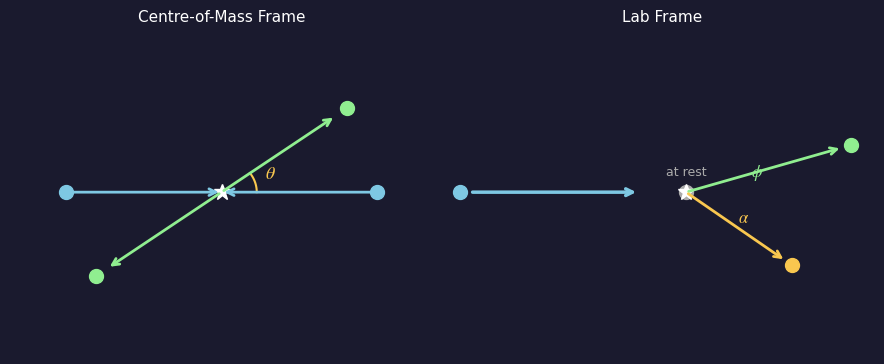

In [15]:
def fig_collision():
    base_style()
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))

    # Left: centre-of-mass frame
    ax = axes[0]
    ax.set_xlim(-3, 3)
    ax.set_ylim(-2.5, 2.5)
    ax.axis('off')

    theta = np.pi / 5

    ax.annotate('', xy=(0, 0), xytext=(-2.2, 0),
                arrowprops=dict(arrowstyle='->', color=BLUE, lw=2))
    ax.annotate('', xy=(0, 0), xytext=( 2.2, 0),
                arrowprops=dict(arrowstyle='->', color=BLUE, lw=2))
    ax.plot(-2.2, 0, 'o', color=BLUE, ms=10)
    ax.plot( 2.2, 0, 'o', color=BLUE, ms=10)

    ax.annotate('', xy=( 2.0 * np.cos(theta),  2.0 * np.sin(theta)),
                xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color=GREEN, lw=2))
    ax.annotate('', xy=(-2.0 * np.cos(theta), -2.0 * np.sin(theta)),
                xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color=GREEN, lw=2))
    ax.plot( 2.2 * np.cos(theta),  2.2 * np.sin(theta), 'o', color=GREEN, ms=10)
    ax.plot(-2.2 * np.cos(theta), -2.2 * np.sin(theta), 'o', color=GREEN, ms=10)

    arc_x = [0.5 * np.cos(t) for t in np.linspace(0, theta, 30)]
    arc_y = [0.5 * np.sin(t) for t in np.linspace(0, theta, 30)]
    ax.plot(arc_x, arc_y, color=YELLOW, lw=1.5)
    ax.text(0.65 * np.cos(theta / 2), 0.65 * np.sin(theta / 2),
            r'$\theta$', color=YELLOW, fontsize=13)
    ax.plot(0, 0, '*', color=WHITE, ms=12)
    ax.set_title('Centre-of-Mass Frame', color=WHITE, fontsize=11)

    # Right: lab frame
    ax2 = axes[1]
    ax2.set_xlim(-0.5, 4)
    ax2.set_ylim(-2.5, 2.5)
    ax2.axis('off')

    ax2.annotate('', xy=(1.5, 0), xytext=(-0.3, 0),
                 arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.5))
    ax2.plot(-0.4, 0, 'o', color=BLUE, ms=10)
    ax2.plot( 2.0, 0, 'o', color=DIM,  ms=10)
    ax2.text(2.0, 0.25, 'at rest', color=DIM, fontsize=9, ha='center')

    phi1 =  np.pi / 8
    phi2 = -np.pi / 4
    ax2.annotate('', xy=(2.0 + 1.8 * np.cos(phi1), 1.8 * np.sin(phi1)),
                 xytext=(2.0, 0),
                 arrowprops=dict(arrowstyle='->', color=GREEN, lw=2))
    ax2.annotate('', xy=(2.0 + 1.5 * np.cos(phi2), 1.5 * np.sin(phi2)),
                 xytext=(2.0, 0),
                 arrowprops=dict(arrowstyle='->', color=YELLOW, lw=2))
    ax2.plot(2.0 + 1.9 * np.cos(phi1), 1.9 * np.sin(phi1), 'o', color=GREEN,  ms=10)
    ax2.plot(2.0 + 1.6 * np.cos(phi2), 1.6 * np.sin(phi2), 'o', color=YELLOW, ms=10)

    ax2.text(2.0 + 0.7 * np.cos(phi1 / 2), 0.7 * np.sin(phi1 / 2) + 0.1,
             r'$\phi$',   color=GREEN,  fontsize=12)
    ax2.text(2.0 + 0.6 * np.cos(phi2 / 2), 0.6 * np.sin(phi2 / 2) - 0.25,
             r'$\alpha$', color=YELLOW, fontsize=12)
    ax2.plot(2.0, 0, '*', color=WHITE, ms=12)
    ax2.set_title('Lab Frame', color=WHITE, fontsize=11)

    plt.tight_layout()
    savefig('fig_collision.png')
    plt.show()

fig_collision()



---
## Package & Download

Run this cell to compress all generated figures into `ch07_figures.zip`
and trigger a download (Colab) or save locally.

In [16]:
ZIP_NAME = 'ch07_figures.zip'

# Pack all PNGs into zip
with zipfile.ZipFile(ZIP_NAME, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir(FIG_DIR)):
        if fname.endswith('.png'):
            fpath = os.path.join(FIG_DIR, fname)
            zf.write(fpath, arcname=fname)

total_kb = os.path.getsize(ZIP_NAME) // 1024
n_files  = len([f for f in os.listdir(FIG_DIR) if f.endswith('.png')])
print(f'Packed {n_files} figures  ->  {ZIP_NAME}  ({total_kb} KB)')
print()
print('Contents:')
for fname in sorted(os.listdir(FIG_DIR)):
    if fname.endswith('.png'):
        kb = os.path.getsize(os.path.join(FIG_DIR, fname)) // 1024
        print(f'  {fname:<45}  {kb:>3} KB')

# Download (Colab) or report local path
print()
try:
    from google.colab import files
    files.download(ZIP_NAME)
    print('Download started.')
except ImportError:
    print(f'Local path: {os.path.abspath(ZIP_NAME)}')


Packed 14 figures  ->  ch07_figures.zip  (680 KB)

Contents:
  fig_collision.png                               28 KB
  fig_energy_momentum.png                         79 KB
  fig_galilean_vs_lorentz.png                     48 KB
  fig_hyperbolic_motion.png                       54 KB
  fig_length_contraction.png                      40 KB
  fig_light_cone.png                              43 KB
  fig_lorentz_factor.png                          43 KB
  fig_rapidity.png                                55 KB
  fig_relativistic_momentum.png                   72 KB
  fig_simultaneity.png                            61 KB
  fig_spacetime_diagram.png                       67 KB
  fig_time_dilation.png                           37 KB
  fig_twin_paradox.png                            43 KB
  fig_velocity_addition.png                       61 KB



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started.
